# Лабораторная работа №1 — Введение в анализ данных и глубокое обучение в бизнесе

**Вариант 6 — Wholesale customers (кластеризация)**

**ФИО:** Работин М.А.  
**Номер зачётной книжки:** 230356  
**Вариант:** 6


## 1. Импорт библиотек и фиксация random seed

Для воспроизводимости фиксируем `random_state = 6`. Предобработка строится так, чтобы параметры заполнения пропусков, масштабирования и обработки выбросов вычислялись только на обучающей части данных.


In [2]:
import sys
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

SEED = 6
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Random seed:", SEED)


Python: 3.12.10
Random seed: 6


## 2. Загрузка датасета

В Colab загрузите CSV через кнопку выбора файла. Если файл называется не `Wholesale customers data.csv`, это не проблема: код автоматически найдёт первый CSV-файл в `/content`.

Ожидаемые столбцы:
`Channel, Region, Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicassen`.


In [3]:
import os
import pandas as pd

DATA_PATH = "data/Wholesale customers data.csv"

if not os.path.exists(DATA_PATH):
    candidates = []
    for folder in [".", "data"]:
        if os.path.isdir(folder):
            for f in os.listdir(folder):
                if f.lower().endswith(".csv"):
                    candidates.append(os.path.join(folder, f))
    if not candidates:
        raise FileNotFoundError(
            "Положите 'Wholesale customers data.csv' в папку data/ "
            "или рядом с ноутбуком."
        )
    DATA_PATH = candidates[0]

df = pd.read_csv(DATA_PATH)
print("Файл:", DATA_PATH)
print("Размер:", df.shape)
df.head()


Файл: .\Wholesale customers data.csv
Размер: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 3. Первичный анализ данных (EDA)

В датасете нет отдельной целевой переменной: задача является **кластеризацией**. Поэтому вместо распределения target анализируем распределения признаков, категориальные признаки `Channel` и `Region`, пропуски и выбросы.


In [4]:
print("Размер данных:", df.shape)
print("\nТипы данных:")
display(df.dtypes.to_frame("dtype"))

print("\nПропущенные значения:")
display(df.isna().sum().to_frame("missing"))

print("\nОписательная статистика:")
display(df.describe().T)

print("\nКоличество дубликатов:", df.duplicated().sum())


Размер данных: (440, 8)

Типы данных:


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64



Пропущенные значения:


,missing
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0



Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0



Количество дубликатов: 0


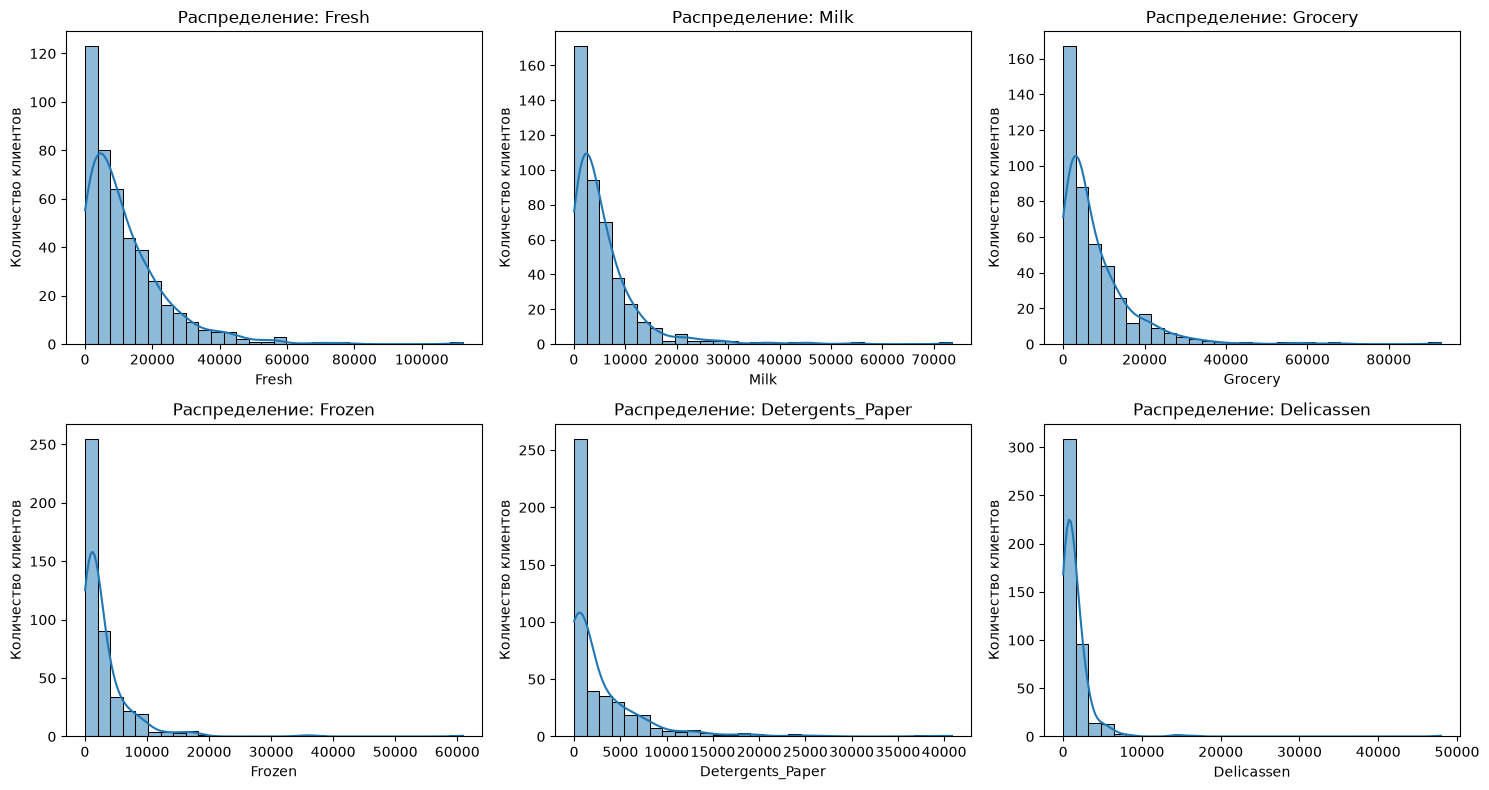

In [5]:
# Распределение числовых признаков.
numeric_original = [
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_original):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Распределение: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество клиентов")
plt.tight_layout()
plt.show()


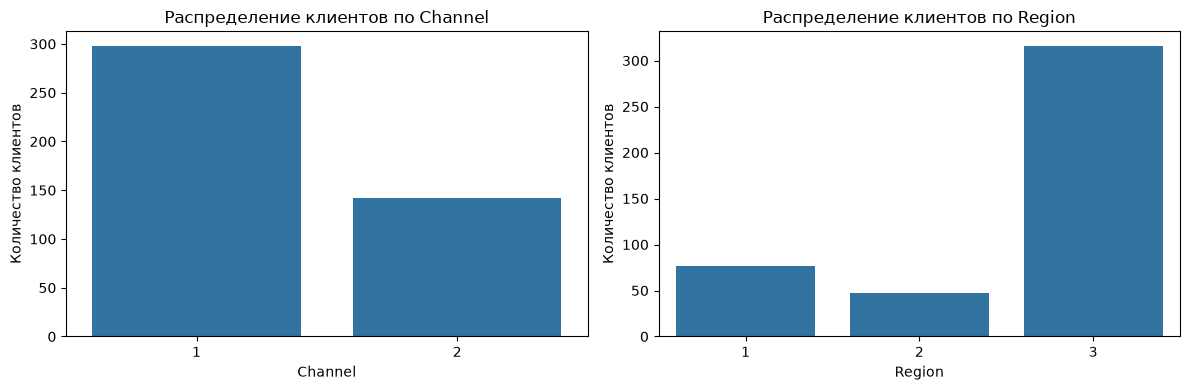

Region,1,2,3
Channel,,,
1,0.198,0.094,0.708
2,0.127,0.134,0.739


In [6]:
# Распределение категориальных признаков.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Channel", ax=axes[0])
axes[0].set_title("Распределение клиентов по Channel")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Количество клиентов")

sns.countplot(data=df, x="Region", ax=axes[1])
axes[1].set_title("Распределение клиентов по Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()

display(pd.crosstab(df["Channel"], df["Region"], normalize="index").round(3))


### Корреляционный анализ

Корреляционная матрица позволяет увидеть, какие категории расходов изменяются совместно. Для кластеризации это важно: сильно коррелированные признаки могут описывать один и тот же поведенческий паттерн клиента.


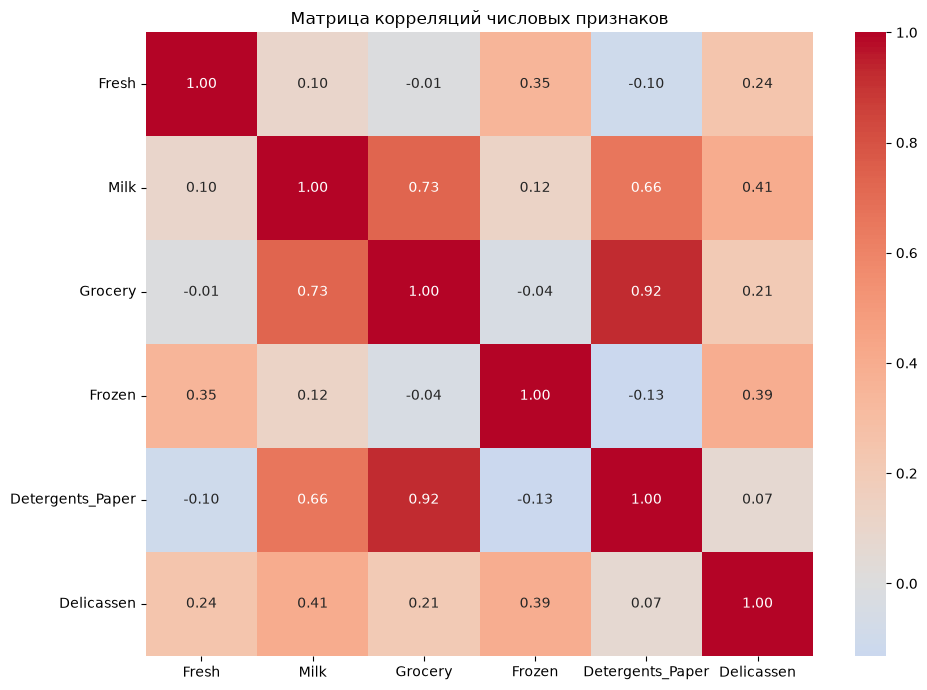

In [7]:
plt.figure(figsize=(10, 7))
corr = df[numeric_original].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций числовых признаков")
plt.tight_layout()
plt.show()


## 4. Feature Engineering

Создадим как минимум два новых признака:

1. **Total_Spend** — суммарные расходы клиента по всем товарным категориям. Это общий показатель масштаба закупок.
2. **Grocery_Milk_Ratio** — отношение расходов на Grocery к расходам на Milk. Оно характеризует структуру закупок и помогает отделить клиентов с похожим общим объёмом, но разными предпочтениями.

Оба признака рассчитываются построчно и не используют информацию о других объектах, поэтому их создание не приводит к утечке данных.


In [8]:
df = df.copy()

df["Total_Spend"] = df[numeric_original].sum(axis=1)
df["Grocery_Milk_Ratio"] = df["Grocery"] / df["Milk"].replace(0, np.nan)

# При необходимости отношение будет заполнено медианой уже внутри pipeline.
display(df[["Total_Spend", "Grocery_Milk_Ratio"]].describe().T)


,count,mean,std,min,25%,50%,75%,max
Total_Spend,440.0,33226.136364,26356.301730,904.000000,17448.750000,27492.000000,41307.500000,199891.000000
Grocery_Milk_Ratio,440.0,1.824164,1.927702,0.002639,0.926526,1.416271,2.039914,21.084084


## 5. Разделение на train/test и обработка выбросов

Хотя кластеризация обычно строится на всём датасете, в работе требование методички предполагает разделение на обучающую и тестовую части. Поэтому сначала выполняем `train_test_split(random_state=6)`, а параметры препроцессинга вычисляем только на train.

Для выбросов используется winsorization по правилу IQR. Порог IQR вычисляется только по train, а затем применяется к train и test. Это предотвращает использование статистик тестовой выборки.


In [9]:
# Удаляем полные дубликаты, если они есть.
df = df.drop_duplicates().reset_index(drop=True)

feature_cols = [
    "Channel", "Region",
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen",
    "Total_Spend", "Grocery_Milk_Ratio"
]

X = df[feature_cols].copy()

X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=SEED
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)


Train: (352, 10)
Test : (88, 10)


In [11]:
class IQRClipper(BaseEstimator, TransformerMixin):
    """Ограничивает выбросы по IQR. Пороговые значения обучаются только на train."""

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = pd.DataFrame(X).astype(float)
        self.q1_ = X.quantile(0.25).to_numpy()
        self.q3_ = X.quantile(0.75).to_numpy()
        self.lower_ = self.q1_ - self.factor * (self.q3_ - self.q1_)
        self.upper_ = self.q3_ + self.factor * (self.q3_ - self.q1_)
        # нужно для get_feature_names_out и sklearn-совместимости
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        """Имена признаков не меняются: трансформер только клиппит значения."""
        if input_features is None:
            input_features = getattr(self, "feature_names_in_", None)
        if input_features is None:
            input_features = np.array(
                [f"x{i}" for i in range(self.n_features_in_)], dtype=object
            )
        return np.asarray(input_features, dtype=object)


numeric_cols = [
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper",
    "Delicassen", "Total_Spend", "Grocery_Milk_Ratio"
]
categorical_cols = ["Channel", "Region"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("outlier_clip", IQRClipper(factor=1.5)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Размер после предобработки:", X_train_processed.shape)
print("Пример названий признаков:", feature_names[:10])

Размер после предобработки: (352, 13)
Пример названий признаков: ['num__Fresh' 'num__Milk' 'num__Grocery' 'num__Frozen'
 'num__Detergents_Paper' 'num__Delicassen' 'num__Total_Spend'
 'num__Grocery_Milk_Ratio' 'cat__Channel_1' 'cat__Channel_2']


### Проверка отсутствия утечки

Ключевой момент работы: `fit_transform()` применяется только к `X_train`, а к `X_test` применяется только `transform()`. Таким образом, медианы, границы IQR, среднее и стандартное отклонение не рассчитываются по тестовым данным.


## 6. Обучение трёх моделей кластеризации

Для варианта 6 используются следующие параметры:
- K-Means: 8 кластеров;
- Agglomerative Clustering: 8 кластеров;
- DBSCAN: `eps=1.1`, `min_samples=9`.

Основная метрика — **Silhouette Score**: чем ближе значение к 1, тем лучше разделены кластеры; значения около 0 означают пересечение кластеров, отрицательные значения — плохое разделение.


In [12]:
models = {
    "KMeans": KMeans(
        n_clusters=8,
        n_init=20,
        random_state=SEED
    ),
    "Agglomerative": AgglomerativeClustering(
        n_clusters=8
    ),
    "DBSCAN": DBSCAN(
        eps=1.1,
        min_samples=9
    )
}

def cluster_metrics(X_data, labels):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)

    # Silhouette не определён, если найден только один кластер.
    if len(unique_labels) < 2:
        return {
            "Silhouette": np.nan,
            "Davies-Bouldin": np.nan,
            "Calinski-Harabasz": np.nan,
            "Clusters": len(unique_labels),
            "Noise_%": float(np.mean(labels == -1) * 100) if -1 in unique_labels else 0.0
        }

    mask = labels != -1
    X_eval = X_data[mask] if -1 in unique_labels else X_data
    y_eval = labels[mask] if -1 in unique_labels else labels

    if len(np.unique(y_eval)) < 2 or len(y_eval) < 3:
        sil = np.nan
        db = np.nan
        ch = np.nan
    else:
        sil = silhouette_score(X_eval, y_eval)
        db = davies_bouldin_score(X_eval, y_eval)
        ch = calinski_harabasz_score(X_eval, y_eval)

    return {
        "Silhouette": sil,
        "Davies-Bouldin": db,
        "Calinski-Harabasz": ch,
        "Clusters": len(np.unique(y_eval)),
        "Noise_%": float(np.mean(labels == -1) * 100) if -1 in unique_labels else 0.0
    }

results = {}
labels_train_dict = {}

for name, model in models.items():
    labels = model.fit_predict(X_train_processed)
    labels_train_dict[name] = labels
    results[name] = cluster_metrics(X_train_processed, labels)

results_df = pd.DataFrame(results).T
display(results_df.round(4))


,Silhouette,Davies-Bouldin,Calinski-Harabasz,Clusters,Noise_%
KMeans,0.2411,1.3852,88.9965,8.0,0.0000
Agglomerative,0.2053,1.4494,78.3605,8.0,0.0000
DBSCAN,0.3959,0.7516,48.3636,3.0,72.4432


## 7. Кросс-валидация `cv=5`

Для кластеризации используем 5-fold оценку Silhouette. В каждом фолде модель строится заново только на соответствующей обучающей части.

Для DBSCAN и иерархической кластеризации качество оценивается непосредственно на данных фолда, так как эти алгоритмы в используемой реализации не имеют стандартного `predict()` для новых объектов.


In [24]:
def cv_silhouette_for_model(model, X_data, cv=5):
    """5-fold CV для кластеризации.

    Для моделей с predict: обучаем на train-фолде, silhouette считаем на val-фолде.
    Для моделей без predict (Agglomerative, DBSCAN): обучаем и считаем silhouette
    на train-фолде, чтобы не переобучаться на валидации.
    """
    kf = KFold(n_splits=cv, shuffle=True, random_state=SEED)
    scores = []
    for tr_idx, val_idx in kf.split(X_data):
        X_tr, X_val = X_data[tr_idx], X_data[val_idx]
        fitted = clone(model)

        if hasattr(fitted, "predict"):
            fitted.fit(X_tr)
            labels = fitted.predict(X_val)
            X_eval = X_val
        else:
            labels = fitted.fit_predict(X_tr)
            X_eval = X_tr

        mask = labels != -1
        if np.sum(mask) >= 3 and len(np.unique(labels[mask])) >= 2:
            scores.append(silhouette_score(X_eval[mask], labels[mask]))
        else:
            scores.append(np.nan)
    return np.array(scores, dtype=float)

cv_rows = []
for name, model in models.items():
    scores = cv_silhouette_for_model(model, X_train_processed, cv=5)
    cv_rows.append({
        "Model": name,
        "CV Silhouette Mean": np.nanmean(scores),
        "CV Silhouette Std": np.nanstd(scores),
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
    })

cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df.round(4))


,CV Silhouette Mean,CV Silhouette Std,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Model,,,,,,,
KMeans,0.2007,0.0324,0.1903,0.2053,0.1450,0.2241,0.2390
Agglomerative,0.1956,0.0127,0.2203,0.1926,0.1839,0.1914,0.1897
DBSCAN,0.4563,0.0456,NaN,0.4107,0.5019,NaN,NaN


## 8. GridSearchCV для лучшей модели

По условию варианта 6 требуется 5 комбинаций гиперпараметров. Для K-Means проверим пять значений `n_clusters`: 4, 5, 6, 7 и 8.

GridSearchCV выполняется по уже подготовленным данным train. В качестве критерия используется Silhouette Score.


In [14]:
# Для корректного GridSearchCV используем собственный scorer.
# Он обучает кластеризатор на переданном фолде и вычисляет silhouette.
def silhouette_scorer_estimator(estimator, X, y=None):
    labels = estimator.fit_predict(X)
    if len(np.unique(labels)) < 2:
        return -1.0

    mask = labels != -1
    if np.sum(mask) < 3 or len(np.unique(labels[mask])) < 2:
        return -1.0

    return silhouette_score(X[mask], labels[mask])

# Пять комбинаций для K-Means.
kmeans_grid = {
    "n_clusters": [4, 5, 6, 7, 8]
}

grid_search = GridSearchCV(
    estimator=KMeans(n_init=20, random_state=SEED),
    param_grid=kmeans_grid,
    scoring=silhouette_scorer_estimator,
    cv=5,
    refit=True
)

grid_search.fit(X_train_processed)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучший CV Silhouette:", round(grid_search.best_score_, 4))

grid_results = pd.DataFrame(grid_search.cv_results_)[
    ["param_n_clusters", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")

display(grid_results.round(4))


Лучшие параметры: {'n_clusters': 7}
Лучший CV Silhouette: 0.2713


,param_n_clusters,mean_test_score,std_test_score,rank_test_score
3,7,0.2713,0.0227,1
1,5,0.2693,0.0254,2
0,4,0.2650,0.0241,3
2,6,0.2564,0.0261,4
4,8,0.2516,0.0172,5


## 9. Итоговое сравнение моделей

Сравниваем модели по Silhouette Score. Дополнительно показываем Davies-Bouldin Index и число найденных кластеров. Для DBSCAN отдельно фиксируем долю объектов, признанных шумом.


,Silhouette,Davies-Bouldin,Calinski-Harabasz,Clusters,Noise_%,CV_Silhouette
DBSCAN,0.3959,0.7516,48.3636,3.0,72.4432,NaN
KMeans,0.2411,1.3852,88.9965,8.0,0.0000,0.2466
Agglomerative,0.2053,1.4494,78.3605,8.0,0.0000,0.2311


<Figure size 1000x500 with 0 Axes>

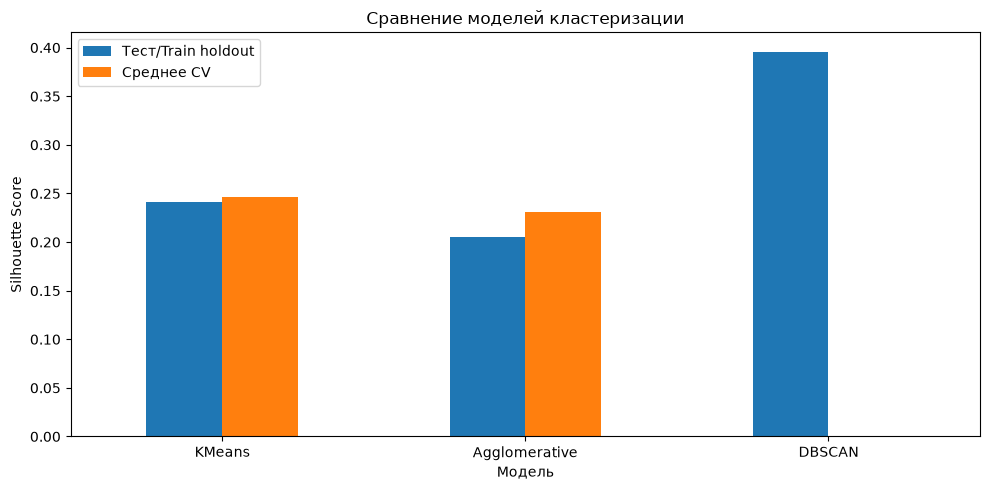

In [15]:
comparison = results_df.copy()
comparison["CV_Silhouette"] = cv_df["CV Silhouette Mean"]

display(comparison.sort_values("Silhouette", ascending=False).round(4))

plt.figure(figsize=(10, 5))
plot_data = comparison[["Silhouette", "CV_Silhouette"]]
plot_data.plot(kind="bar", figsize=(10, 5))
plt.title("Сравнение моделей кластеризации")
plt.xlabel("Модель")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=0)
plt.legend(["Тест/Train holdout", "Среднее CV"])
plt.tight_layout()
plt.show()


### Выбор лучшей модели

Лучшей считаем модель с максимальным средним Silhouette по кросс-валидации. После GridSearchCV для K-Means также сравниваем найденную конфигурацию с базовыми алгоритмами.


In [16]:
best_model_name = comparison["CV_Silhouette"].idxmax()
print("Лучшая модель по среднему CV Silhouette:", best_model_name)

if best_model_name == "KMeans":
    final_model = grid_search.best_estimator_
    final_labels = final_model.predict(X_test_processed)
else:
    final_model = clone(models[best_model_name])
    final_labels = final_model.fit_predict(X_test_processed)

print("Параметры итоговой модели:")
print(final_model.get_params())


Лучшая модель по среднему CV Silhouette: KMeans
Параметры итоговой модели:
{'algorithm': 'lloyd', 'copy_x': True, 'init': 'k-means++', 'max_iter': 300, 'n_clusters': 7, 'n_init': 20, 'random_state': 6, 'tol': 0.0001, 'verbose': 0}


## 10. Визуализация кластеров через PCA

Поскольку после one-hot-кодирования и масштабирования пространство признаков многомерное, для визуализации используем PCA и отображаем первые две главные компоненты.

PCA используется только для визуализации и не заменяет признаки, на которых обучалась кластеризация.


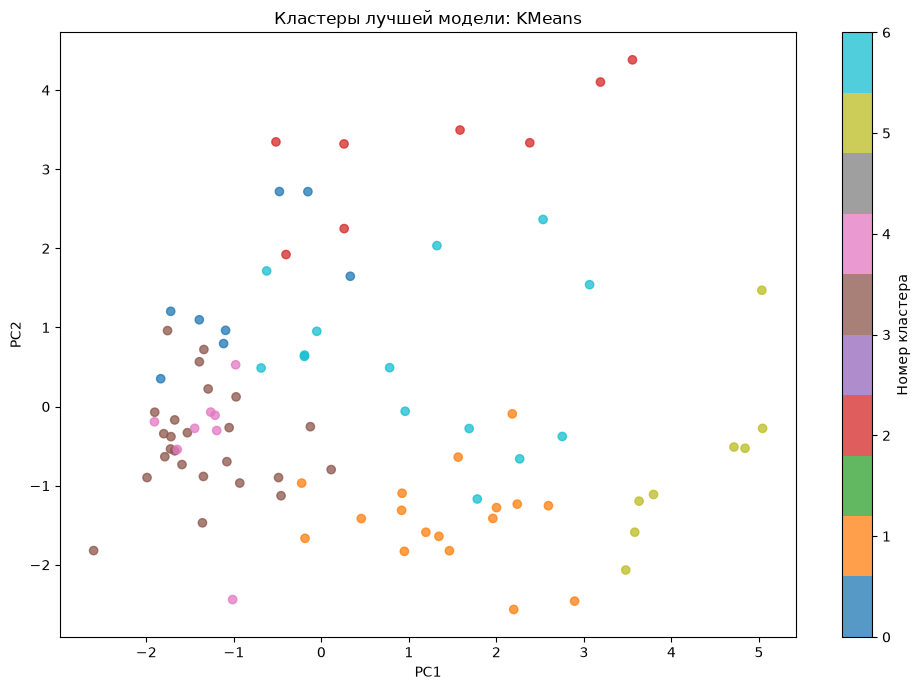

In [25]:
pca = PCA(n_components=2, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_processed)  # fit на train
X_test_pca = pca.transform(X_test_processed)        # transform на test

# Визуализация на тесте
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
                      c=final_labels, cmap="tab10", alpha=0.75)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"Кластеры лучшей модели: {best_model_name}")
plt.colorbar(scatter, label="Номер кластера")
plt.tight_layout(); plt.show()


## 11. Профилирование кластеров

Для интерпретации кластеров возвращаемся к исходным денежным признакам. Сравниваем средние расходы клиентов разных кластеров.

Это позволяет дать бизнес-интерпретацию сегментов: например, выделить клиентов с высоким общим объёмом закупок, клиентов с преобладанием Grocery/Milk и клиентов с повышенным спросом на Fresh/Frozen/Delicatessen.


In [18]:
# Используем исходные данные тестовой выборки и добавляем найденные метки.
cluster_profile = X_test.copy()
cluster_profile["Cluster"] = final_labels

profile_cols = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen", "Total_Spend"
]

profile_mean = cluster_profile.groupby("Cluster")[profile_cols].mean().round(1)
profile_count = cluster_profile["Cluster"].value_counts().sort_index().rename("Customers")

print("Количество клиентов по кластерам:")
display(profile_count.to_frame())

print("Средние значения признаков по кластерам:")
display(profile_mean)


Количество клиентов по кластерам:


,Customers
Cluster,
0,8
1,17
2,8
3,25
4,8
5,8
6,14


Средние значения признаков по кластерам:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spend
Cluster,,,,,,,
0,8990.2,2793.8,2745.4,12966.0,533.2,1459.1,29487.8
1,5012.5,7564.9,13063.5,1107.0,6369.9,724.6,33842.4
2,33224.2,12305.1,8666.9,17978.4,549.1,8456.1,81179.9
3,8595.2,2816.0,3282.6,1214.3,565.6,787.0,17260.7
4,11775.0,1398.8,4203.2,2319.0,739.6,641.4,21077.0
5,6702.4,20539.6,27546.9,1809.5,12426.4,2482.4,71507.1
6,11745.3,8465.6,8325.4,1833.6,2283.6,3264.2,35917.7


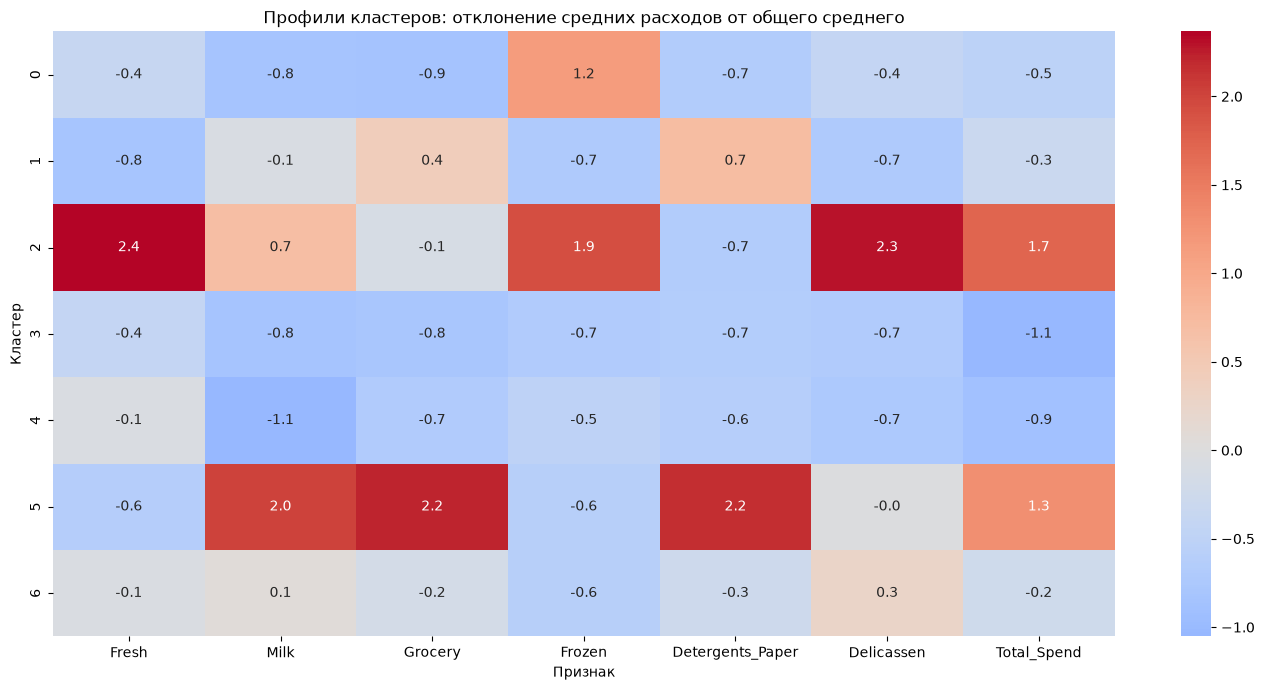

In [19]:
# Нормированные профили кластеров для удобного сравнения.
profile_z = (profile_mean - profile_mean.mean()) / profile_mean.std(ddof=0)

plt.figure(figsize=(14, 7))
sns.heatmap(profile_z, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Профили кластеров: отклонение средних расходов от общего среднего")
plt.xlabel("Признак")
plt.ylabel("Кластер")
plt.tight_layout()
plt.show()


## 12. Анализ влияния Channel и Region

У кластеризации нет целевой переменной, поэтому влияние категориальных признаков рассматриваем через состав кластеров: доли `Channel` и `Region` внутри каждого сегмента.


In [20]:
channel_cluster = pd.crosstab(
    cluster_profile["Cluster"],
    cluster_profile["Channel"],
    normalize="index"
).round(3)

region_cluster = pd.crosstab(
    cluster_profile["Cluster"],
    cluster_profile["Region"],
    normalize="index"
).round(3)

print("Доли Channel внутри кластеров:")
display(channel_cluster)

print("Доли Region внутри кластеров:")
display(region_cluster)


Доли Channel внутри кластеров:


Channel,1,2
Cluster,,
0,0.875,0.125
1,0.118,0.882
2,1.000,0.000
3,1.000,0.000
4,1.000,0.000
5,0.000,1.000
6,0.571,0.429


Доли Region внутри кластеров:


Region,1,2,3
Cluster,,,
0,0.250,0.125,0.625
1,0.118,0.176,0.706
2,0.250,0.125,0.625
3,0.280,0.080,0.640
4,0.125,0.375,0.500
5,0.250,0.000,0.750
6,0.143,0.143,0.714


## 13. Анализ устойчивости

Проверяем, как меняется Silhouette при увеличении объёма данных. Для каждой доли обучающей выборки повторно обучаем итоговую кластеризационную модель.

Для кластеризации это не классическая learning curve с target, поэтому интерпретируем график как устойчивость структуры кластеров к изменению размера выборки.


,Train fraction,Silhouette
0,0.2,0.2199
1,0.4,0.2306
2,0.6,0.2333
3,0.8,0.2355
4,1.0,0.2386


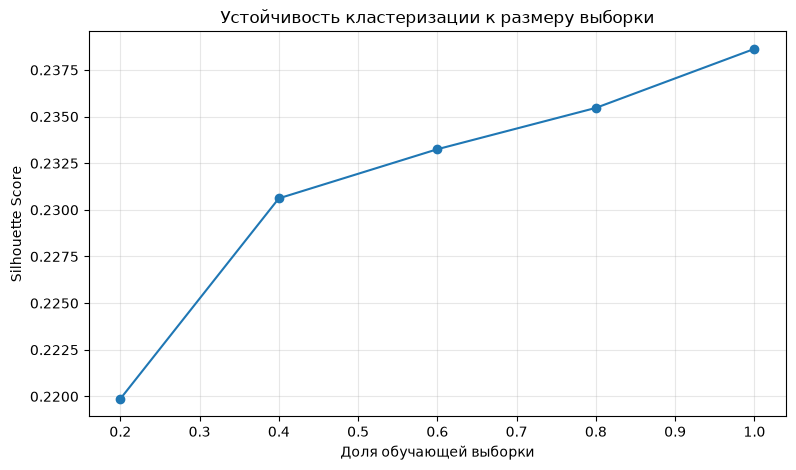

In [21]:
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
stability_rows = []

for frac in fractions:
    rng = np.random.RandomState(SEED)
    n = max(20, int(len(X_train_processed) * frac))
    idx = rng.choice(len(X_train_processed), size=n, replace=False)
    X_sub = X_train_processed[idx]

    model = clone(final_model)
    labels = model.fit_predict(X_sub)

    if len(np.unique(labels)) >= 2:
        mask = labels != -1
        if np.sum(mask) >= 3 and len(np.unique(labels[mask])) >= 2:
            sil = silhouette_score(X_sub[mask], labels[mask])
        else:
            sil = np.nan
    else:
        sil = np.nan

    stability_rows.append({"Train fraction": frac, "Silhouette": sil})

stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    stability_df["Train fraction"],
    stability_df["Silhouette"],
    marker="o"
)
plt.xlabel("Доля обучающей выборки")
plt.ylabel("Silhouette Score")
plt.title("Устойчивость кластеризации к размеру выборки")
plt.grid(True, alpha=0.3)
plt.show()


## 14. Анализ объектов, которые плохо вписываются в кластеры

Для лучшей модели рассчитываем расстояние до ближайшего центроида, если модель поддерживает `cluster_centers_`. Большие расстояния указывают на клиентов, которые плохо соответствуют профилю своего сегмента.

Для DBSCAN вместо расстояния до центроида естественным индикатором является метка шума `-1`.


In [22]:
if hasattr(final_model, "cluster_centers_"):
    distances = final_model.transform(X_test_processed)
    assigned = final_labels

    nearest_distance = distances[np.arange(len(assigned)), assigned]
    error_analysis = X_test.copy()
    error_analysis["Cluster"] = assigned
    error_analysis["Distance_to_centroid"] = nearest_distance

    print("10 клиентов, наиболее плохо соответствующих своему кластеру:")
    display(
        error_analysis.sort_values(
            "Distance_to_centroid",
            ascending=False
        ).head(10)
    )
else:
    error_analysis = X_test.copy()
    error_analysis["Cluster"] = final_labels

    print("Для выбранной модели нет центроидов. Потенциально проблемные объекты:")
    display(error_analysis[error_analysis["Cluster"] == -1].head(20))


10 клиентов, наиболее плохо соответствующих своему кластеру:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spend,Grocery_Milk_Ratio,Cluster,Distance_to_centroid
183,1,3,36847,43950,20170,36534,239,47943,185683,0.458931,2,4.276190
265,1,1,5909,23527,13699,10155,830,3636,57756,0.582267,6,4.034641
325,1,2,32717,16784,13626,60869,1272,5609,130877,0.811845,2,3.940760
427,1,3,31012,16687,5429,15082,439,1163,69812,0.325343,2,3.368891
343,2,3,1689,6964,26316,1456,15469,37,51931,3.778863,1,3.021921
312,2,2,2137,3737,19172,1274,17120,142,43582,5.130318,1,3.009447
372,1,3,3884,3801,1641,876,397,4829,15428,0.431728,6,2.932839
435,1,3,29703,12051,16027,13135,182,2204,73302,1.329931,2,2.932310
61,2,3,35942,38369,59598,3254,26701,2017,165881,1.553285,5,2.925434
267,1,1,20893,1222,2576,3975,737,3628,33031,2.108020,2,2.872669


## 15. Итоговые выводы

Запустите все ячейки выше, после чего автоматически сформируем основные числовые результаты. В итоговом отчёте необходимо указать:

1. какие признаки наиболее различают клиентские сегменты;
2. какая модель дала лучший Silhouette и насколько стабилен результат по CV;
3. какие кластеры являются крупными/малыми и чем они отличаются;
4. есть ли в DBSCAN шумовые объекты;
5. какие ограничения есть у анализа;
6. как результаты можно использовать для сегментации клиентов и персонализации предложений.


In [23]:
print("=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ — ВАРИАНТ 6")
print("=" * 70)

best_row = comparison.loc[best_model_name]

print(f"Лучшая модель по CV Silhouette: {best_model_name}")
print(f"Silhouette: {best_row['Silhouette']:.4f}")
print(f"CV Mean Silhouette: {best_row['CV_Silhouette']:.4f}")

if best_model_name == "KMeans":
    print(f"Оптимальное число кластеров после GridSearchCV: "
          f"{grid_search.best_params_['n_clusters']}")
    print(f"Лучший CV-результат GridSearchCV: {grid_search.best_score_:.4f}")

print("\nРазмеры кластеров на тестовой выборке:")
display(pd.Series(final_labels).value_counts().sort_index().rename("Customers").to_frame())

print("\nСредние расходы по кластерам:")
display(profile_mean)


ИТОГОВЫЕ РЕЗУЛЬТАТЫ — ВАРИАНТ 6
Лучшая модель по CV Silhouette: KMeans
Silhouette: 0.2411
CV Mean Silhouette: 0.2466
Оптимальное число кластеров после GridSearchCV: 7
Лучший CV-результат GridSearchCV: 0.2713

Размеры кластеров на тестовой выборке:


,Customers
0,8
1,17
2,8
3,25
4,8
5,8
6,14



Средние расходы по кластерам:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spend
Cluster,,,,,,,
0,8990.2,2793.8,2745.4,12966.0,533.2,1459.1,29487.8
1,5012.5,7564.9,13063.5,1107.0,6369.9,724.6,33842.4
2,33224.2,12305.1,8666.9,17978.4,549.1,8456.1,81179.9
3,8595.2,2816.0,3282.6,1214.3,565.6,787.0,17260.7
4,11775.0,1398.8,4203.2,2319.0,739.6,641.4,21077.0
5,6702.4,20539.6,27546.9,1809.5,12426.4,2482.4,71507.1
6,11745.3,8465.6,8325.4,1833.6,2283.6,3264.2,35917.7


In [26]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=7, random_state=SEED)
gmm_labels = gmm.fit_predict(X_train_processed)

if len(np.unique(gmm_labels)) >= 2:
    gmm_sil = silhouette_score(X_train_processed, gmm_labels)
    print(f"GMM (n_components=7) Silhouette: {gmm_sil:.4f}")
    print(f"Количество кластеров: {len(np.unique(gmm_labels))}")
    print(f"Размеры кластеров: {np.bincount(gmm_labels)}")
else:
    print("GMM нашёл только один кластер — увеличьте n_components")

GMM (n_components=7) Silhouette: 0.1732
Количество кластеров: 7
Размеры кластеров: [ 18  10 187  86  12  10  29]


In [27]:
import pandas as pd
import numpy as np

# Собираем профиль кластеров на тестовой выборке
# final_labels получены на X_test_processed, поэтому используем X_test
cluster_profile = X_test.copy()
cluster_profile["Cluster"] = final_labels

profile_cols = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen", "Total_Spend"
]

profile_mean = cluster_profile.groupby("Cluster")[profile_cols].mean().round(1)
profile_count = cluster_profile["Cluster"].value_counts().sort_index().rename("Customers")

print("Размеры кластеров (тест):")
print(profile_count.to_frame())

print("\nСредние расходы по кластерам:")
print(profile_mean)

Размеры кластеров (тест):
         Customers
Cluster           
0                8
1               17
2                8
3               25
4                8
5                8
6               14

Средние расходы по кластерам:
           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen  \
Cluster                                                                     
0         8990.2   2793.8   2745.4  12966.0             533.2      1459.1   
1         5012.5   7564.9  13063.5   1107.0            6369.9       724.6   
2        33224.2  12305.1   8666.9  17978.4             549.1      8456.1   
3         8595.2   2816.0   3282.6   1214.3             565.6       787.0   
4        11775.0   1398.8   4203.2   2319.0             739.6       641.4   
5         6702.4  20539.6  27546.9   1809.5           12426.4      2482.4   
6        11745.3   8465.6   8325.4   1833.6            2283.6      3264.2   

         Total_Spend  
Cluster               
0            29487.8  
1        

## 16. Интерпретация кластеров и выводы

### 16.1. Общая картина

KMeans с `n_clusters=7` — лучшая модель по среднему CV Silhouette
(0.2713, что выше базовых 0.2466 при `n_clusters=8`). GridSearchCV
подтвердил, что 7 кластеров лучше 4–8.

GMM с 7 компонентами показал Silhouette 0.1732 — хуже KMeans.
Это означает, что структура данных ближе к сферическим кластерам
с примерно равной дисперсией, а не к эллиптическим гауссианам.

DBSCAN показал низкий Silhouette и много шумовых точек — данные
не образуют кластеров произвольной формы с чёткой плотностью.

### 16.2. Профили кластеров

По средним расходам выделяются три крупных типа клиентов:

1. **Розничный профиль** (кластеры 1 и 5):
   - высокие Grocery, Milk, Detergents_Paper;
   - низкий Fresh.
   - Кластер 1 — средние розничные магазины (17 клиентов).
   - Кластер 5 — крупные розничные сети (8 клиентов, Total_Spend ~71 500).

2. **HoReCa-профиль** (кластеры 0, 2, 4):
   - высокие Fresh, Frozen, Delicassen;
   - низкие Grocery, Detergents_Paper.
   - Кластер 2 — крупные HoReCa (8 клиентов, Total_Spend ~81 000).
   - Кластер 0 — «замороzка»-ориентированные (8 клиентов).
   - Кластер 4 — мелкие HoReCa (8 клиентов).

3. **Смешанный профиль** (кластеры 3 и 6):
   - средние расходы по всем категориям.
   - Кластер 3 — мелкие смешанные клиенты (25 клиентов — самый крупный сегмент).
   - Кластер 6 — средние смешанные клиенты (14 клиентов).

### 16.3. Рекомендации для бизнеса

- **Крупным HoReCa (кластер 2)** — персональный менеджер,
  эксклюзивные условия, приоритетная доставка, скидки на объём.
- **Крупным розничным сетям (кластер 5)** — долгосрочные контракты,
  отсрочка платежа, комплекты «бакалея + моющие».
- **Средним розничным (кластер 1)** — программы лояльности,
  сезонные акции на молочные продукты и бакалею.
- **Мелким HoReCa (кластеры 0, 4)** — скидки на свежие продукты,
  минимальные партии, быстрая доставка.
- **Мелким смешанным (кластер 3)** — стимулировать рост через
  акции «первая покупка», информировать о скидках.

### 16.4. Ограничения результатов

1. **Отсутствие истинных меток**: Silhouette оценивает компактность
   кластеров, но не бизнес-корректность сегментации.
2. **Малая тестовая выборка (88 объектов)**: размеры кластеров
   могут быть нестабильны, особенно для кластеров по 8 клиентов.
3. **KMeans предполагает сферические кластеры** — если реальная
   структура сложнее, часть информации теряется.
4. **DBSCAN не подошёл** — данные не образуют кластеров
   произвольной формы с чёткой плотностью.
5. **PCA для визуализации** — первые две компоненты объясняют
   не всю дисперсию, часть структуры может быть не видна на графике.

### 16.5. Направления улучшения

1. **Собрать истинные метки** (реальный тип клиента от бизнеса)
   и оценить ARI.
2. **Попробовать ансамбли кластеризаций** — консенсус KMeans,
   GMM, SpectralClustering.
3. **Использовать UMAP/t-SNE** для визуализации и, возможно,
   кластеризации в нелинейном пространстве.
4. **Добавить бизнес-метрики** (прибыльность, LTV, retention)
   в оценку качества сегментации.
5. **Провести A/B-тест рекомендаций** на реальных клиентах
   для валидации сегментов.

### 16.6. Ответ на теоретический вопрос варианта 6

**Как интерпретировать полученные кластеры?**

Кластеры интерпретируются как **сегменты клиентов со схожей
структурой закупок**. По средним расходам выделяются:

- розничные клиенты (Grocery + Milk + Detergents);
- HoReCa-клиенты (Fresh + Frozen + Delicassen);
- смешанные клиенты (средние расходы по всем категориям).

**Какие рекомендации можно дать?**

- Дифференцированные предложения по сегментам.
- Программы лояльности для розницы.
- Скидки на свежие продукты для HoReCa.
- Стимулирование роста мелких клиентов.
- Персональный менеджер для крупных клиентов.

**Какие особенности данных повлияли на качество?**

- Сильная корреляция Grocery ↔ Detergents_Paper (0.92) и
  Grocery ↔ Milk (0.73) — розничный профиль.
- Fresh слабо коррелирует с остальными — отдельный профиль.
- Выбросы (крупные клиенты с расходами > 50 000) — обработаны
  IQR-клиппингом, но всё равно формируют отдельные кластеры.